# Compute Liveability for Each Suburb

Liveability is built from suburb-level median distances to amenities (and crime rate). Every feature is preferred to be small for good liveability, so the pipeline is:

1. Remove properties that are exact duplicates by latitude and longitude (these are multiple leased flats in the same building and bias liveability calculation).
2. Convert distance to the CBD from kilometres to metres so that all distance features share the same units.
3. Drop suburbs with fewer than 5 properties.
4. Take the median value for each feature within each suburb group.
5. Apply `log10(1 + x)` to reduce right skew (the `+ 1` keeps zero distances valid).
6. Standardise each log median across suburb groups (mean 0, sample variance 1) so that no feature outweighs another purely through its scale.
7. Combine the features using a weighted sum.
8. Flip the direction and rescale so that higher means more liveable.

## Imports
Libraries used to aggregate, log-transform, standardise and plot the data.

In [42]:
from pathlib import Path

import contextily as cx
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.cm import ScalarMappable
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.patches import Rectangle
from shapely.geometry import box

### Read in Final Parquet Data

In [43]:
PARQUET_PATH = (
    "../rea_data/analysis/rental_data_merged_final/"
    "rentals_final.parquet"
)

df = pd.read_parquet(PARQUET_PATH)
df.shape

(12316, 120)

## Remove duplicate properties

Properties with identical coordinates are treated as duplicates, and only
the first occurrence is kept. This is done so that suburb counts and centroids reflect unique locations.

In [44]:
n_before = len(df)
df = df.dropna(subset=["lat", "lon"])
n_missing_coordinates = n_before - len(df)

df = df.drop_duplicates(subset=["lat", "lon"], keep="first")
n_duplicates = n_before - n_missing_coordinates - len(df)

print(
    f"Removed {n_missing_coordinates} rows with missing coordinates and "
    f"{n_duplicates} duplicates; {len(df)} properties remain"
)

Removed 0 rows with missing coordinates and 1310 duplicates; 11006 properties remain


## Convert distance to CBD to metres

Every other distance feature is in metres, but `dist_to_cbd_km_driving` is in kilometres. The `+ 1` in `log10(1 + x)` is negligible for values in the hundreds or thousands (metres) but not for values like 0.5 (km), so the CBD distance is converted to metres first. This only adds a column in memory; the parquet file is untouched.

In [45]:
df["dist_to_cbd_m_driving"] = df["dist_to_cbd_km_driving"] * 1000

## Distribution of properties per suburb

Shows how many unique property locations each suburb has after duplicates are removed. The dashed line marks `MIN_PROPERTIES`, the cut-off below which a suburb is dropped because its median is too unreliable.

1. Set the minimum number of properties a suburb needs to stand alone.
2. Count unique property locations per suburb.
3. Plot the distribution, with the cut-off marked.

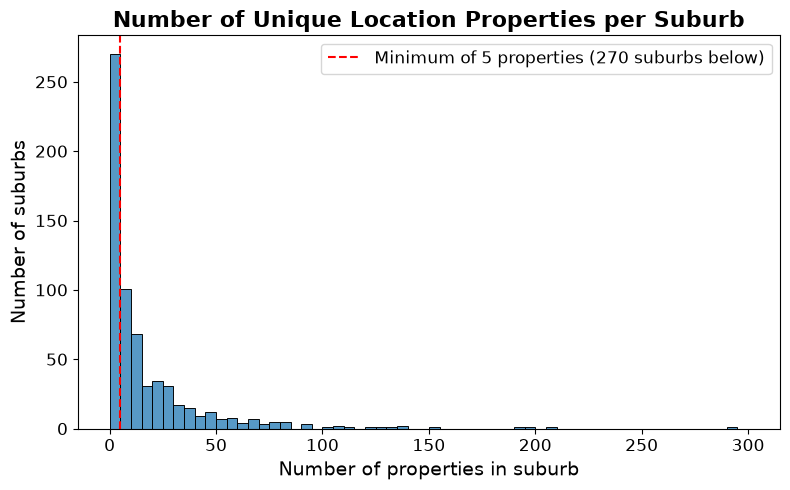

In [46]:
MIN_PROPERTIES = 5

properties_per_suburb = df.groupby("suburb").size()
n_suburbs_below_minimum = (properties_per_suburb < MIN_PROPERTIES).sum()

# Bin width of 5 so that the cut-off sits exactly on a bin edge
bin_edges = np.arange(0, properties_per_suburb.max() + 10, 5)

count_figure, count_axis = plt.subplots(figsize=(8, 5))

sns.histplot(properties_per_suburb, bins=bin_edges, ax=count_axis)

count_axis.axvline(
    MIN_PROPERTIES,
    color="red",
    linestyle="--",
    label=(
        f"Minimum of {MIN_PROPERTIES} properties "
        f"({n_suburbs_below_minimum} suburbs below)"
    ),
)

count_axis.set_title(
    "Number of Unique Location Properties per Suburb",
    fontsize=16,
    fontweight="bold",
)
count_axis.set_xlabel("Number of properties in suburb", fontsize=14)
count_axis.set_ylabel("Number of suburbs", fontsize=14)
count_axis.tick_params(axis="both", labelsize=12)
count_axis.legend(fontsize=12)

count_figure.tight_layout()
plt.show()

## Drop suburbs with fewer than 5 properties

A median based on very few properties is noisy. Instead of merging small suburbs into their neighbours, every suburb with fewer than `MIN_PROPERTIES` unique locations (counted after duplicates are removed) is dropped. Each remaining suburb is its own `suburb_group`, so later cells work unchanged.

In [47]:
properties_per_suburb = df.groupby("suburb").size()
suburbs_to_keep = properties_per_suburb[
    properties_per_suburb >= MIN_PROPERTIES
].index

n_suburbs_dropped = len(properties_per_suburb) - len(suburbs_to_keep)
n_properties_dropped = (~df["suburb"].isin(suburbs_to_keep)).sum()

df = df[df["suburb"].isin(suburbs_to_keep)].copy()
df["suburb_group"] = df["suburb"]

print(
    f"Dropped {n_suburbs_dropped} suburbs ({n_properties_dropped} "
    f"properties); {len(suburbs_to_keep)} suburbs remain"
)

Dropped 270 suburbs (484 properties); 374 suburbs remain


## Standardised log median by suburb

Given a feature column (a distance in metres, or crime rate), this function:

1. Takes the median value for each suburb group.
2. Applies `log10(1 + x)` to the medians. The values here are in the hundreds to hundreds of thousands, so the `+ 1` barely changes the shape but makes zero values valid.
3. Standard scales the log medians across suburb groups to mean 0 and s² = 1 (sample variance, `ddof=1`).
4. Returns a Series indexed by suburb group.

Standardising across suburb groups (not properties) means each suburb group counts once. Higher values mean the suburb group is further from the amenity (or has a higher crime rate) than average.

In [48]:
def standardised_log_median_by_suburb(
    df: pd.DataFrame,
    feature_column: str,
    suburb_column: str = "suburb_group",
) -> pd.Series:
    """Return each suburb group's standardised log10(1 + median) value.

    Higher values mean the suburb group is further away (or has a higher
    crime rate) than average.
    """
    median_values = df.groupby(suburb_column)[feature_column].median()
    log_median_values = np.log10(1 + median_values)

    return (
        log_median_values - log_median_values.mean()
    ) / log_median_values.std(ddof=1)

## Feature weights

One weight per feature in the liveability calculation. The weights are determined by the category weights used by the Economist Intelligence Unit Global Liveability Index. Because every standardised feature will have mean 0 and variance 1, these weights now directly reflect relative importance.

Category weights: Stability (25%), Culture & Environment (25%), Healthcare (20%), Infrastructure (20%), Education (10%). The weights below sum to 1, as the `weights.sum()` output confirms.

The mapping of features to categories and the splits within each category are judgement calls. Distance to the CBD uses the metre version created above.

In [49]:
weights = pd.Series(
    {
        "school_primary_road_distance_m": 0.05,     # Education
        "school_secondary_road_distance_m": 0.05,   # Education
        "hospital_road_distance_m": 0.13,           # Healthcare
        "medical_doctors_road_distance_m": 0.07,    # Healthcare
        "crime_rate": 0.25,                         # Stability
        "sports_rec_road_distance_m": 0.075,        # Culture & Environment
        "park_local_road_distance_m": 0.075,        # Culture & Environment
        "shopping_centre_road_distance_m": 0.1,     # Culture & Environment
        "bus_stops_PTV_road_distance_m": 0.05,      # Infrastructure
        "train_stations_PTV_road_distance_m": 0.1,  # Infrastructure
        "dist_to_cbd_m_driving": 0.05,              # Infrastructure
    }
)
assert np.isclose(weights.sum(), 1.0), f"Weights sum to {weights.sum()}"
weights.sum()

np.float64(1.0)

## Effect of the log transform

For each feature, the left panel shows the distribution of raw suburb groups' medians and the right panel shows the distribution of `log10(1 + suburb median)`. Distance features are in metres; crime rate is not a distance, so its axis labels say so. The skewness of each distribution is in the panel title (0 means symmetric; large positive values mean a long right tail). The log version should be much closer to symmetric.

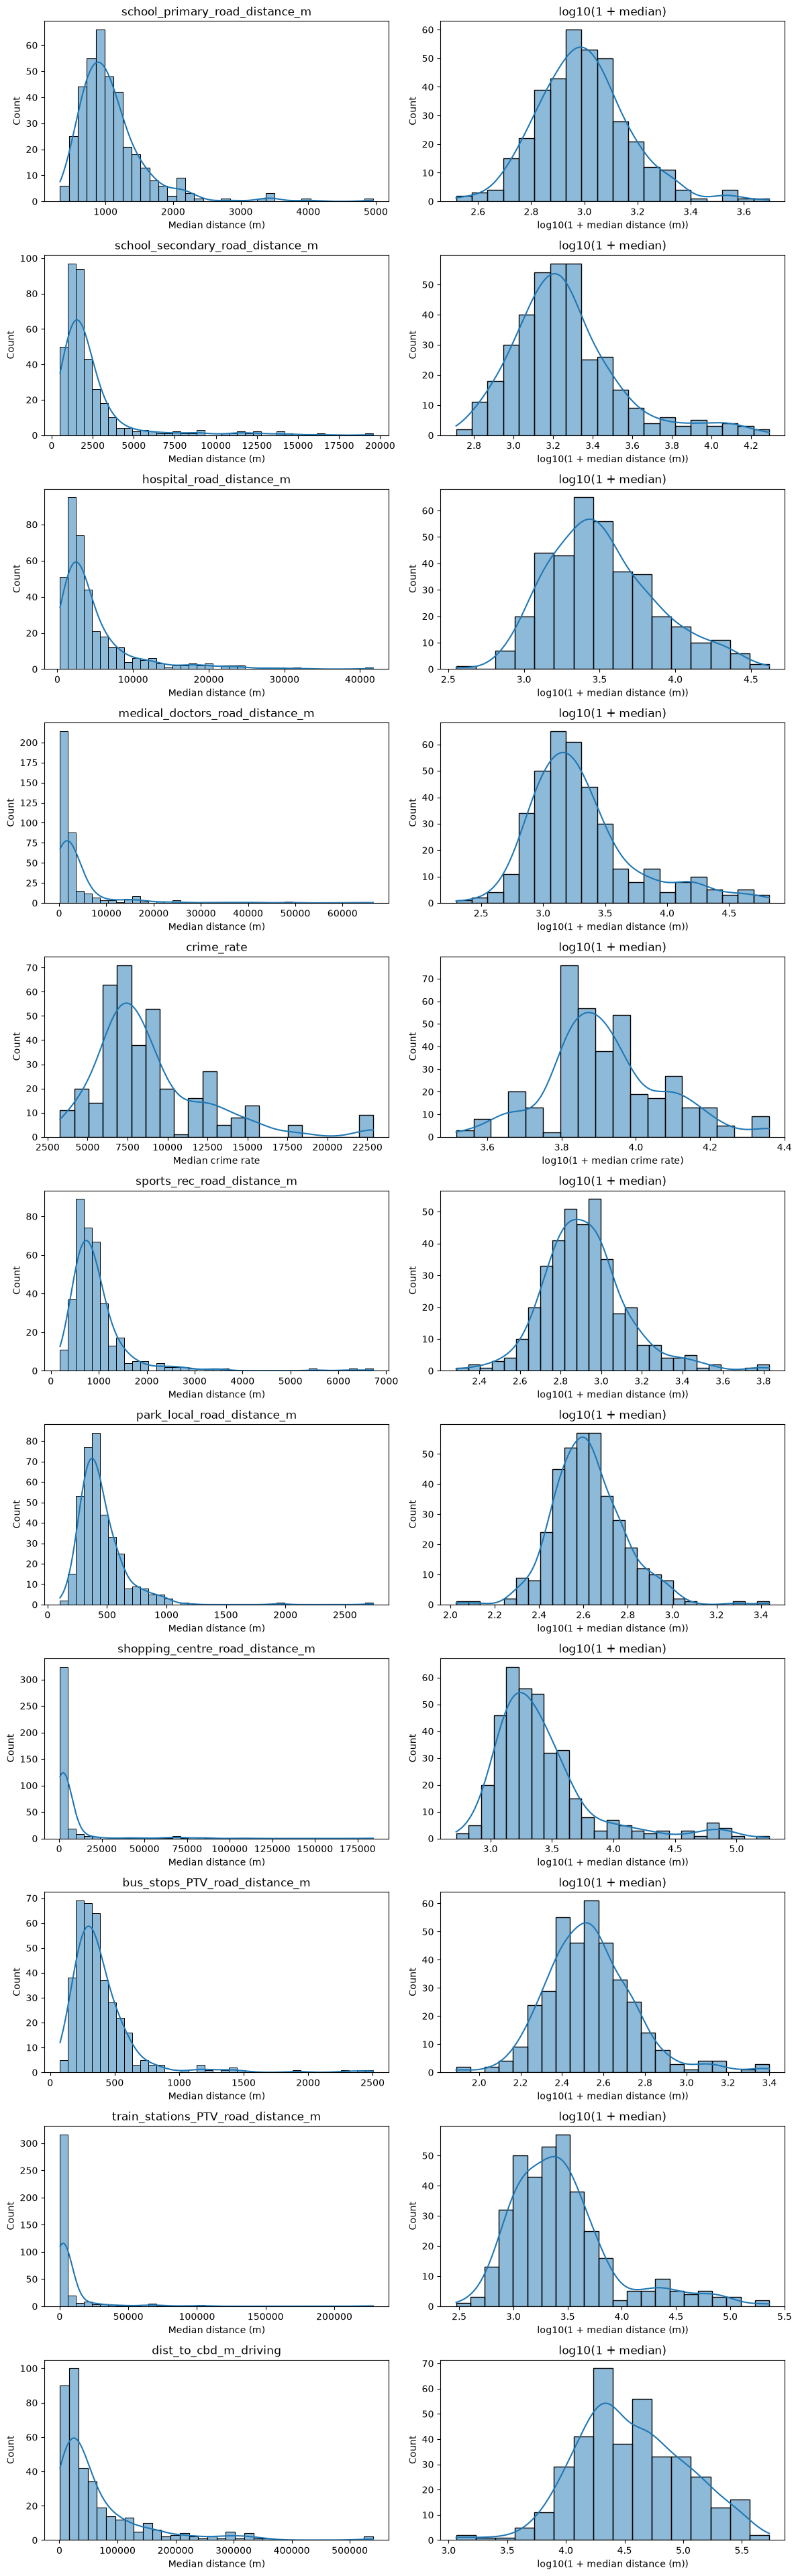

In [50]:
# Features that are not distances, with the text used in axis labels
NON_DISTANCE_LABELS = {"crime_rate": "crime rate"}

# group by suburb, compute median of each feature in liveability calculation
median_values = pd.DataFrame(
    {
        column: df.groupby("suburb_group")[column].median()
        for column in weights.index
    }
)

# apply log base 10 transform (+1 to ensure 0 distance doesn't fail)
log_median_values = np.log10(1 + median_values)

# all distributions will be visualised on the same plot window
fig, axes = plt.subplots(len(weights), 2, figsize=(12, 3.5 * len(weights)))

for row, column in enumerate(weights.index):
    raw = median_values[column]
    logged = log_median_values[column]

    # set to non-distance label column, otherwise revert to distance (m)
    label = NON_DISTANCE_LABELS.get(column, "distance (m)")

    # kde plot of distribution of raw medians
    sns.histplot(raw, kde=True, ax=axes[row, 0])
    axes[row, 0].set_title(column)
    axes[row, 0].set_xlabel(f"Median {label}")

    # kde plot of distribution of logged medians, alongside the raw medians
    sns.histplot(logged, kde=True, ax=axes[row, 1])
    axes[row, 1].set_title("log10(1 + median)")
    axes[row, 1].set_xlabel(f"log10(1 + median {label})")

plt.tight_layout()
plt.show()

# Extract Hospital Plot for Presentation

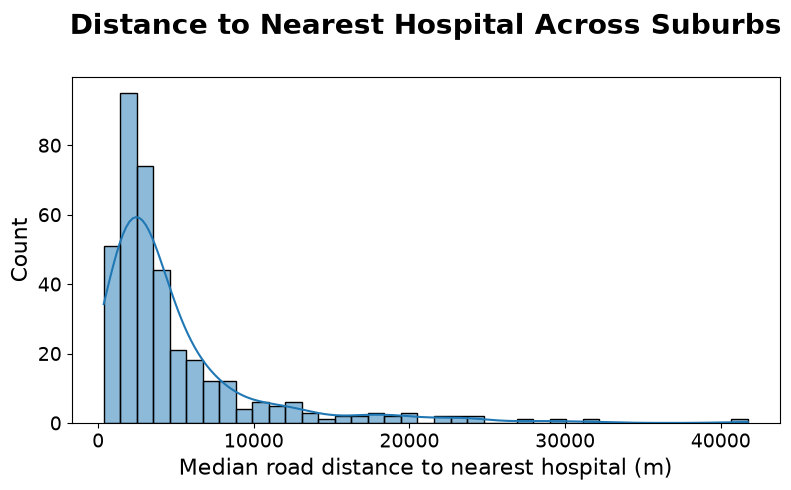

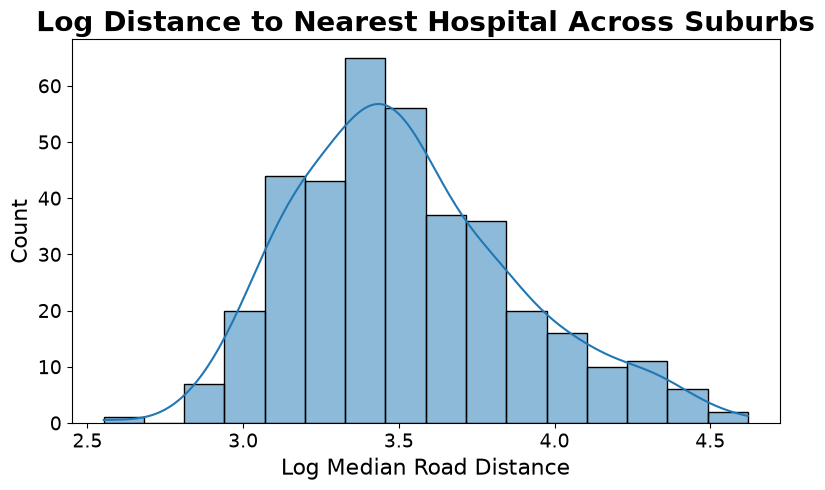

In [51]:
HOSPITAL_COLUMN = "hospital_road_distance_m"

hospital_median_distance = df.groupby("suburb_group")[HOSPITAL_COLUMN].median()
hospital_log_median_distance = np.log10(1 + hospital_median_distance)

raw_figure, raw_axis = plt.subplots(figsize=(8, 5))

sns.histplot(hospital_median_distance, kde=True, ax=raw_axis)

raw_axis.set_title(
    "Distance to Nearest Hospital Across Suburbs\n",
    fontsize=20,
    fontweight="bold",
)
raw_axis.set_xlabel(
    "Median road distance to nearest hospital (m)", fontsize=16
)
raw_axis.set_ylabel("Count", fontsize=16)
raw_axis.tick_params(axis="both", labelsize=14)

raw_figure.tight_layout()
plt.show()

log_figure, log_axis = plt.subplots(figsize=(8, 5))

sns.histplot(hospital_log_median_distance, kde=True, ax=log_axis)

log_axis.set_title(
    "Log Distance to Nearest Hospital Across Suburbs",
    fontsize=20,
    fontweight="bold",
)
log_axis.set_xlabel("Log Median Road Distance", fontsize=16)
log_axis.set_ylabel("Count", fontsize=16)
log_axis.tick_params(axis="both", labelsize=14)

log_figure.tight_layout()
plt.show()

## Standardise every feature

Builds a DataFrame with one row per suburb and one column of standardised log median values per feature.

In [52]:
standardised_features = pd.DataFrame(
    {
        column: standardised_log_median_by_suburb(df, column)
        for column in weights.index
    }
)

missing_counts = standardised_features.isna().sum()
assert missing_counts.sum() == 0, (
    f"Missing standardised values:\n{missing_counts[missing_counts > 0]}"
)
standardised_features.head()

standardised_features.head()

,school_primary_road_distance_m,school_secondary_road_distance_m,hospital_road_distance_m,medical_doctors_road_distance_m,crime_rate,sports_rec_road_distance_m,park_local_road_distance_m,shopping_centre_road_distance_m,bus_stops_PTV_road_distance_m,train_stations_PTV_road_distance_m,dist_to_cbd_m_driving
suburb_group,,,,,,,,,,,
ABBOTSFORD,-0.962876,-0.936419,-1.019778,-0.788446,1.718263,-1.600942,-0.881175,-1.259949,0.688229,-0.763467,-1.311537
ABERFELDIE,-0.765284,-2.020909,-0.482326,-0.082824,-0.233530,-3.043623,1.663407,0.025888,-3.013641,-0.338571,-0.894418
AIRPORT WEST,-0.093477,0.546458,0.268730,0.411974,-0.233530,-0.012625,-0.068318,-0.635351,-0.886293,0.636998,-0.581406
ALBANVALE,-0.974087,0.787340,0.009758,-0.132393,0.344559,-0.162857,-0.465460,-0.608364,-0.048696,0.070316,-0.263736
ALBERT PARK,-1.640329,-0.591862,0.160566,-1.766940,1.455526,-1.036774,-1.386988,-0.484515,0.363447,-0.123681,-3.249405


## Weighted sum

Combines the standardised features using the weights. Since every feature is worse when large, a **higher** weighted sum means the suburb is **further** from amenities or has **more** crime, so it is **less** liveable.

In [53]:
# Multiply each feature column by its weight (matched on column name),
# then sum across features (axis=1) for one score per suburb group.
# skipna=False makes a missing feature produce NaN instead of counting
# as an average value.
weighted_sum = standardised_features.mul(weights).sum(axis=1, skipna=False)

## Flip and rescale to a liveability score

The direction is flipped once, at the end, so that higher means more liveable. Two versions are produced:

- **`liveability`**: min-max scaled to 0-1, where 1 is the best suburb and 0 is the worst. This is relative to the best and worst suburbs, not literally "% liveable", and a single extreme suburb compresses the rest.
- **`liveability_percentile`**: percentile rank, where 0.8 means the suburb is more liveable than 80% of suburbs. This is robust to outliers and easier to explain.

In [54]:
weighted_sum_range = weighted_sum.max() - weighted_sum.min()
liveability = (weighted_sum.max() - weighted_sum) / weighted_sum_range
liveability_percentile = (-weighted_sum).rank(pct=True)

suburb_scores = pd.DataFrame(
    {
        "liveability": liveability,
        "liveability_percentile": liveability_percentile,
    }
).reset_index()

suburb_scores.sort_values("liveability", ascending=False).head(10)

,suburb_group,liveability,liveability_percentile
130,ELSTERNWICK,1.000000,1.000000
344,TRAVANCORE,0.982932,0.997326
53,BRIGHTON,0.965062,0.994652
168,HAWTHORN,0.958019,0.991979
172,HEIDELBERG,0.948269,0.989305
136,ESSENDON NORTH,0.941779,0.986631
305,SANDRINGHAM,0.938920,0.983957
169,HAWTHORN EAST,0.938654,0.981283
115,DONCASTER,0.926743,0.978610
151,GLEN HUNTLY,0.921453,0.975936


## Add the number of properties per suburb group

The liveability scores are calculated per suburb group, so each group's score is shown alongside the number of unique property locations in that group (after duplicate coordinates are removed). This shows how many locations each score is based on.

In [55]:
property_counts = df.groupby("suburb_group").size()

suburb_scores["n_properties"] = suburb_scores["suburb_group"].map(
    property_counts
)

suburb_scores.sort_values("liveability", ascending=False).head(10)

,suburb_group,liveability,liveability_percentile,n_properties
130,ELSTERNWICK,1.000000,1.000000,28
344,TRAVANCORE,0.982932,0.997326,7
53,BRIGHTON,0.965062,0.994652,44
168,HAWTHORN,0.958019,0.991979,53
172,HEIDELBERG,0.948269,0.989305,26
136,ESSENDON NORTH,0.941779,0.986631,15
305,SANDRINGHAM,0.938920,0.983957,20
169,HAWTHORN EAST,0.938654,0.981283,43
115,DONCASTER,0.926743,0.978610,47
151,GLEN HUNTLY,0.921453,0.975936,6


## Export liveability scores

Writes both scores per suburb group. `liveability` is min-max scaled
(0 to 1), and `liveability_percentile` is the percentile rank, where 1.0
means the suburb group is more liveable than every other suburb group.

In [56]:
LIVEABILITY_SCORES_FILE = Path("../external_data/liveability_scores.csv")

SCORE_COLUMNS = ["liveability", "liveability_percentile"]

scores_export = suburb_scores[["suburb_group"] + SCORE_COLUMNS].copy()

assert scores_export["suburb_group"].is_unique, "Duplicate suburb groups"
assert scores_export[SCORE_COLUMNS].notna().all().all(), (
    "Missing liveability scores"
)
assert scores_export["liveability"].between(0, 1).all(), (
    "liveability outside 0-1"
)
assert scores_export["liveability_percentile"].between(0, 1).all(), (
    "liveability_percentile outside 0-1"
)

scores_export.round(
    {"liveability": 4, "liveability_percentile": 4}
).to_csv(LIVEABILITY_SCORES_FILE, index=False)

print(f"Wrote {len(scores_export)} rows to {LIVEABILITY_SCORES_FILE}")
scores_export.head()

Wrote 374 rows to ../external_data/liveability_scores.csv


,suburb_group,liveability,liveability_percentile
0,ABBOTSFORD,0.741098,0.676471
1,ABERFELDIE,0.845272,0.911765
2,AIRPORT WEST,0.669758,0.478610
3,ALBANVALE,0.668629,0.462567
4,ALBERT PARK,0.729705,0.633690


# Top Liveability Suburbs

In [57]:
# Display the five suburbs with the highest liveability scores
top_five_liveability = scores_export.nlargest(5, "liveability")
print(top_five_liveability)

    suburb_group  liveability  liveability_percentile
130  ELSTERNWICK     1.000000                1.000000
344   TRAVANCORE     0.982932                0.997326
53      BRIGHTON     0.965062                0.994652
168     HAWTHORN     0.958019                0.991979
172   HEIDELBERG     0.948269                0.989305


## Liveability map

Each suburb group is drawn as a circle at the mean latitude and longitude
of its properties, coloured by its liveability percentile (red = less
liveable, green = more liveable). The map is saved as an image,
`liveability_map.png`, over an Esri street map background. Set
`MAP_BOUNDS` to `None` to fit every suburb group instead of just Melbourne.

In [58]:
group_centroids = df.groupby("suburb_group")[["lat", "lon"]].mean()

map_data = suburb_scores.merge(
    group_centroids,
    left_on="suburb_group",
    right_index=True,
    how="left",
    validate="one_to_one",
)
assert map_data[["lat", "lon"]].notna().all().all(), "Missing centroids"
map_data.head()

,suburb_group,liveability,liveability_percentile,n_properties,lat,lon
0,ABBOTSFORD,0.741098,0.676471,27,-37.805822,145.001330
1,ABERFELDIE,0.845272,0.911765,5,-37.756346,144.899918
2,AIRPORT WEST,0.669758,0.478610,26,-37.723904,144.880895
3,ALBANVALE,0.668629,0.462567,5,-37.745490,144.767198
4,ALBERT PARK,0.729705,0.633690,5,-37.843086,144.954674


Showing 374 of 374 suburb groups


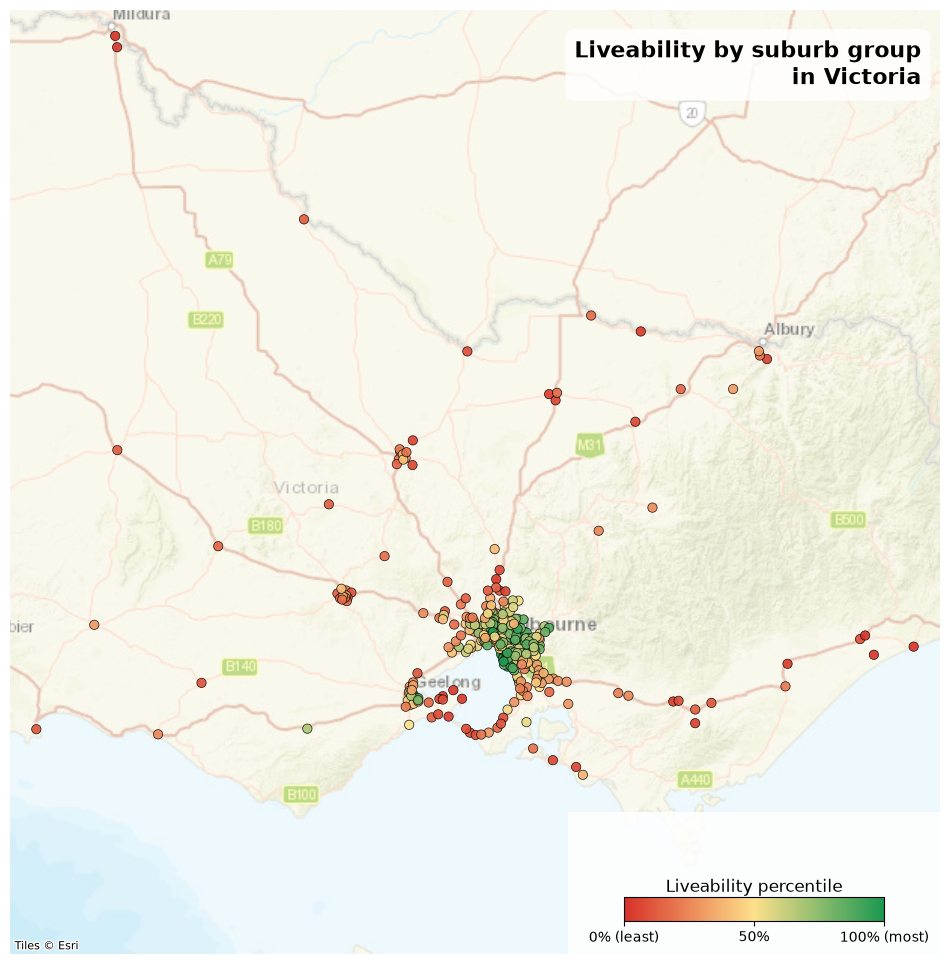

In [59]:
# --- Settings -------------------------------------------------------------

# Colours from least liveable (red) through the middle (yellow) to most
# liveable (green). Used for both the markers and the colour bar.
COLOURS = ["#d73027", "#fee08b", "#1a9850"]

BASE_TILES = (
    "https://server.arcgisonline.com/ArcGIS/rest/services/"
    "World_Street_Map/MapServer/tile/{z}/{y}/{x}"
)
USE_BASEMAP = True    # needs an internet connection
BASEMAP_ALPHA = 0.5   # 0 = invisible, 1 = fully opaque
MARKER_SIZE = 45      # area of each circle, in points squared
MARKER_ALPHA = 0.9    # slightly see-through so overlapping dots show
FIG_WIDTH = 12        # inches; height is derived from the map bounds
DPI = 200

# West, south, east, north in degrees. None fits every suburb group,
# which crops the map tightly to the data instead of a fixed 16:9 box.
MAP_BOUNDS = None

PAD_FRACTION = 0.03           # breathing room around the points
LEGEND_ROOM_FRACTION = 0.20   # extra strip at the bottom for the legend
MAP_TITLE = "Liveability by suburb group\nin Victoria"

MAP_IMAGE_FILE = Path("../Figures/liveability_map.png")

# --- Map data -------------------------------------------------------------

# One point per suburb group, in metres (EPSG:3857) to match the tiles.
map_points = gpd.GeoDataFrame(
    map_data,
    geometry=gpd.points_from_xy(map_data["lon"], map_data["lat"]),
    crs=4326,
).to_crs(epsg=3857)

if MAP_BOUNDS is None:
    min_x, min_y, max_x, max_y = map_points.total_bounds
else:
    min_x, min_y, max_x, max_y = (
        gpd.GeoSeries([box(*MAP_BOUNDS)], crs=4326)
        .to_crs(epsg=3857)
        .total_bounds
    )

# --- View extent ----------------------------------------------------------

# Pad evenly, then add extra room at the bottom for the legend box.
padding = PAD_FRACTION * max(max_x - min_x, max_y - min_y)
min_x, max_x = min_x - padding, max_x + padding
max_y = max_y + padding
min_y = min_y - padding - LEGEND_ROOM_FRACTION * (max_y - min_y)

in_view = map_points.cx[min_x:max_x, min_y:max_y]
print(f"Showing {len(in_view)} of {len(map_points)} suburb groups")
assert len(in_view) > 0, "No suburb groups fall inside the map bounds"

# --- Colour scale ---------------------------------------------------------

# 0 is always red and 1 is always green.
colour_map = LinearSegmentedColormap.from_list("liveability", COLOURS)
colour_norm = Normalize(vmin=0, vmax=1)

# --- Figure ---------------------------------------------------------------

# Height follows the data extent, so there is no spare space at the sides.
fig, ax = plt.subplots(
    figsize=(FIG_WIDTH, FIG_WIDTH * (max_y - min_y) / (max_x - min_x))
)
ax.set_xlim(min_x, max_x)
ax.set_ylim(min_y, max_y)

# Street map background (alpha fades it towards white).
if USE_BASEMAP:
    try:
        cx.add_basemap(
            ax,
            source=BASE_TILES,
            crs=map_points.crs,
            alpha=BASEMAP_ALPHA,
            attribution="Tiles © Esri",
        )
    except Exception as err:  # offline, blocked tiles, etc.
        print(f"Basemap skipped: {err}")

# One circle per suburb group, coloured by its liveability percentile.
ax.scatter(
    in_view.geometry.x,
    in_view.geometry.y,
    c=in_view["liveability_percentile"],
    cmap=colour_map,
    norm=colour_norm,
    s=MARKER_SIZE,
    edgecolor="black",
    linewidth=0.5,
    alpha=MARKER_ALPHA,
    zorder=3,
)

# add_basemap can change the limits, so set them again.
ax.set_xlim(min_x, max_x)
ax.set_ylim(min_y, max_y)
ax.set_axis_off()

# --- Title box (top right, over the map) ----------------------------------

ax.text(
    0.98,
    0.97,
    MAP_TITLE,
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=16,
    fontweight="bold",
    bbox={
        "boxstyle": "round,pad=0.4",
        "facecolor": "white",
        "alpha": 0.85,
        "edgecolor": "none",
    },
    zorder=6,
)

# --- Legend box (bottom right, in the reserved strip) ---------------------

legend_background = Rectangle(
    (0.60, 0.0),
    0.40,
    0.15,
    transform=ax.transAxes,
    facecolor="white",
    alpha=0.85,
    edgecolor="none",
    zorder=5,
)
ax.add_patch(legend_background)

colour_bar_axis = ax.inset_axes([0.66, 0.035, 0.28, 0.025])
colour_bar_axis.set_zorder(6)

colour_bar = fig.colorbar(
    ScalarMappable(norm=colour_norm, cmap=colour_map),
    cax=colour_bar_axis,
    orientation="horizontal",
)
colour_bar.set_ticks([0, 0.5, 1])
colour_bar.set_ticklabels(["0% (least)", "50%", "100% (most)"])
colour_bar.set_label("Liveability percentile", fontsize=12)
colour_bar_axis.xaxis.set_label_position("top")

# --- Output ---------------------------------------------------------------

MAP_IMAGE_FILE.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(
    MAP_IMAGE_FILE,
    dpi=DPI,
    bbox_inches="tight",
    pad_inches=0.05,
    facecolor="white",
)
plt.show()